**EEG–Eye-Tracking Multimodal Research | Presented by: Reza Saadatyar (2026)**

**03 | EEG and Gaze Preprocessing, Feature Extraction and Neurophysiology**

![Observed 18-person EEG and gaze feature extraction and quality evidence](../../images/03_preprocessing_features_and_neurophysiology.svg)

**Research question:** Can reproducible, modality-specific EEG and eye-tracking features be extracted from the **same 630 eligible ZuCo 2.0 reading windows**, retaining original participant identities, task labels and frozen Train/Validation/Test assignments?

**Objective:** Extract a compact EEG spectral/RMS representation and gaze/event summaries from each paired 12-second window, retain **six two-second feature bins** per modality, verify window-to-feature alignment, and inspect a separate Train-only fixation-locked raw EEG example.

**Dataset and task:** ZuCo 2.0, NEMAR `nm000279`, release `v1.0.0`; **18 participants**, **36 original NR/TSR Run-1 recordings** and **630 eligible windows**. The target is **Normal Reading (NR) versus Task-Specific Reading (TSR)**. The frozen participant split contains **11 Train / 3 Validation / 4 reserved Test people**, corresponding to **371/99/160 windows**.

**Recorded results:** All **630/630** source windows produced eight finite window-mean EEG/gaze features and matching six-bin temporal representations. **No extraction failures or excluded windows** occurred. EEG and gaze arrays were saved separately, each with shape **(630, 6, 4)**. All **36 person/task groups** remain represented, including `sub-YAK / NR` with just one window. The Train-derived quality table identifies **`gaze_valid_fraction` as a constant predictor** (standard deviation 0), while the other seven predictors vary in Train.

**Scientific boundary:** These results verify technical feature availability and source identity retention; they do **not** establish model accuracy, brain-source localisation, physiological explanation of reading, or reliable independent EEG–EyeLink clock synchronisation. The fixation-locked raw single-channel example is descriptive, not a validated fixation-related potential (FRP). The reserved Test data are represented for provenance, **not fitted or scored in this notebook**.


**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")

if not repo_path.exists():
    subprocess.run(
        ["git", "clone", "-q", repo_url, str(repo_path)], check=True
    )

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("eeg_eye_tracking_fusion")

# ---------------------------- 2. Standard Library ----------------------------
import importlib.util
import json
import random
import shutil
import sys

# ---------------------- 3. Colab Dependency Preparation ----------------------
if importlib.util.find_spec("mne") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "-q", "install",
         "mne>=1.6,<2"],
        check=True,
    )

# ----------------- 4. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd
from scipy.signal import butter, sosfiltfilt

# ------------------- 5. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style

# ----------------- 6. Shared and Project Research Utilities ------------------
from core.output_download import download_outputs_from_colab
from zuco_io import open_run, session
from alignment import ensure_disjoint_registry
from features import (
    EEG_FIELDS, GAZE_FIELDS, eeg_channels, extract_window, clean_eeg,
)

# ---------------------------- 7. Reproducibility -----------------------------
SEED = 17
random.seed(SEED)
np.random.seed(SEED)

# ------------------- 8. Output Directory and Setup Summary -------------------
work = root / "eeg_eye_tracking_fusion"
output_dir = work / "output"
output_dir.mkdir(parents=True, exist_ok=True)
raw_dir = Path("/content/zuco2_source_cache")
raw_dir.mkdir(parents=True, exist_ok=True)
plot_style(font_family="DejaVu Sans", figure_dpi=100)
print("Project outputs:", output_dir)
print("Temporary source cache:", raw_dir)
print("Python:", sys.version.split()[0])
print("Free disk (GiB):", round(
    shutil.disk_usage("/content").free / 2**30, 2,
))


Local changes kept; continuing with the current checkout. Conflicting Git update deferred.
Project outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/eeg_eye_tracking_fusion/output
Temporary source cache: /content/zuco2_source_cache
Python: 3.13.18
Free disk (GiB): 103.99


**02. Verify the Frozen Paired-Window Protocol**

Notebook 03 reads the original **18-person Source Manifest** (`01_source_manifest.csv`), the saved protocol (`01_protocol.json`) and the current Stage-02 paired-window registry and timing report. It checks that **all selected participants** are present in both source and window records, that every person remains in a single partition, and that each eligible window corresponds to the same original person, task, run and split.

**Executed input evidence:** **36 original Run-1 recordings** and **630 eligible 12-second windows**, covering **341 NR** and **289 TSR** windows. Source labels and participant roles remain unchanged.

| Partition | NR | TSR | Total windows | People |
| --- | ---: | ---: | ---: | ---: |
| Train | 201 | 170 | **371** | 11 |
| Validation | 60 | 39 | **99** | 3 |
| Test (reserved) | 80 | 80 | **160** | 4 |
| **All** | **341** | **289** | **630** | **18** |

The protocol specifies **six two-second feature bins** per 12-second window. Source timing is based on nominal EEG/eye sampling rates and BIDS eye `StartTime`; the run-level alignment reports do **not** claim independently verified inter-device drift. These limitations are inherited from Notebook 02, not resolved by feature extraction.


In [3]:
# ============= 02. Verify Paired Windows and Modality Contracts ==============

required = [
    "01_source_manifest.csv", "01_protocol.json",
    "02_window_registry.csv", "02_alignment_quality.csv",
]
missing = [p for p in required if not (output_dir / p).is_file()]
if missing:
    raise FileNotFoundError(
        f"Missing upstream source or alignment outputs: {missing}"
    )

source = pd.read_csv(
    output_dir / "01_source_manifest.csv",
    dtype={"participant_id": str},
)
registry = pd.read_csv(
    output_dir / "02_window_registry.csv",
    dtype={"participant_id": str},
)
alignment_quality = pd.read_csv(
    output_dir / "02_alignment_quality.csv",
    dtype={"participant_id": str},
)
protocol = json.loads((output_dir / "01_protocol.json").read_text())

if (protocol.get('selected_people') != source.participant_id.nunique()
        or set(registry.participant_id) != set(source.participant_id)):
    raise ValueError(
        'Stage-01/02 cohorts differ. Rerun the changed upstream stage '
        'before extracting features.')
ensure_disjoint_registry(registry)
selected = registry.loc[registry.eligible].copy()
if selected.empty:
    raise ValueError("No eligible paired windows from Notebook 02")

# A selected window must belong to its original source run and split.
join_keys = ["participant_id", "task", "run"]
source_roles = source[join_keys + ["split"]].drop_duplicates()
linked = selected.merge(
    source_roles, on=join_keys, how="left",
    suffixes=("_window", "_source"), validate="many_to_one",
)
if (linked.split_source.isna().any() or not
        linked.split_window.eq(linked.split_source).all()):
    raise ValueError("Window source identities or participant roles differ")

window_length = float(protocol["window_seconds"])
bin_seconds = float(protocol["bin_seconds"])
bins_ratio = window_length / bin_seconds
if not np.isclose(bins_ratio, round(bins_ratio)):
    raise ValueError("Window length must divide into equal feature bins")
BINS = int(round(bins_ratio))
REQUEST = session()

print("Recorded source participants:", source.participant_id.nunique())
print("Recorded original runs:", len(source))
print("Eligible paired windows:", len(selected))
print("Feature bins per window:", BINS)
print("Independent clock drift verified:",
      alignment_quality.drift_verified.astype(str).str.lower().eq(
          "true").all())
display(
    selected.groupby(["split", "task"])
    .agg(windows=("window_id", "size"),
         participants=("participant_id", "nunique"))
    .reset_index()
)


Recorded source participants: 18
Recorded original runs: 36
Eligible paired windows: 630
Feature bins per window: 6
Independent clock drift verified: False


,split,task,windows,participants
0,test,nr,80,4
1,test,tsr,80,4
2,train,nr,201,11
3,train,tsr,170,11
4,validation,nr,60,3
5,validation,tsr,39,3


**03. Extract EEG and Gaze Features from Matched Windows**

The EEG stream is read from the original BrainVision recording, using the predefined **16 available native EEG channels**. Each selected 12-second segment is channel-centred and bandpass-filtered at **1–40 Hz** for feature computation. Within each of **six two-second bins**, the EEG representation comprises channel-aggregated **theta (4–8 Hz), alpha (8–13 Hz) and beta (13–30 Hz) log bandpower**, plus **RMS amplitude in µV**. These compact features are descriptive and do not provide anatomical source localisation.

For the *same window and bins*, EyeLink-derived gaze features comprise **finite x/y coordinate fraction**, **median gaze speed (pixels/s)**, **median pupil measurement (source units)** and **fixation-event occupancy fraction**. Original fixation events supply the event occupancy information; source text content is not a model input.

**Executed result:** The extraction loop processed **all 630 eligible windows** across **36 source runs**, retaining **630 matching EEG/gaze feature pairs** and logging **zero extraction exceptions**. The resulting `03_features.csv` preserves each window's identity, task, Run 1, participant, partition and 12-second time bounds.

The six-bin arrays retain the **original numerical feature values and units**. Imputation and model scaling are deferred to Train-fitted estimators in the downstream modelling notebooks.


In [4]:
# ============== 03. Extract Matched Modality-Separated Features ==============

feature_rows, signal_windows, gaze_windows, accepted, issues = (
    [], [], [], [], [])
for _, run in source.iterrows():
    subset = selected.loc[
        selected.participant_id.eq(run.participant_id) &
        selected.task.eq(run.task) &
        selected.run.eq(run.run)]
    if subset.empty:
        continue
    preceding_ok = len(accepted)
    preceding_issues = len(issues)
    raw, eye, events, eye_meta, _ = open_run(run, raw_dir, REQUEST)
    channels = eeg_channels(raw, count=16)
    try:
        for _, row in subset.iterrows():
            try:
                eeg_seq, gaze_seq = extract_window(
                    raw, eye, events, eye_meta, row, channels,
                    bin_seconds=float(protocol['bin_seconds']))
                if eeg_seq.shape != (BINS, len(EEG_FIELDS)):
                    raise ValueError('EEG feature shape mismatch')
                if gaze_seq.shape != (BINS, len(GAZE_FIELDS)):
                    raise ValueError('Gaze feature shape mismatch')
                fields = {name: float(np.nanmean(eeg_seq[:, j]))
                          for j, name in enumerate(EEG_FIELDS)}
                fields.update({
                    name: float(np.nanmean(gaze_seq[:, j]))
                    for j, name in enumerate(GAZE_FIELDS)})
                feature_rows.append({**row.to_dict(), **{
                    'eeg_' + name: value
                    for name, value in fields.items()
                    if name in EEG_FIELDS}, **{
                    'gaze_' + name: value
                    for name, value in fields.items()
                    if name in GAZE_FIELDS}})
                signal_windows.append(eeg_seq)
                gaze_windows.append(gaze_seq)
                accepted.append(str(row.window_id))
            except (ValueError, FloatingPointError) as exc:
                issues.append({'window_id': row.window_id,
                               'reason': str(exc)})
    finally:
        raw.close()
    print(
        "Processed:", run.participant_id, run.task,
        "| candidate windows:", len(subset),
        "| retained:", len(accepted) - preceding_ok,
        "| excluded:", len(issues) - preceding_issues,
    )
features = pd.DataFrame(feature_rows)
if features.empty:
    raise RuntimeError('No paired temporal features were produced')
if features.window_id.duplicated().any():
    raise ValueError("Feature extraction duplicated original window IDs")
print("Extracted paired feature windows:", len(features))
print("Feature extraction issues:", len(issues))
display(features.head())


Processed: sub-YAC nr | candidate windows: 20 | retained: 20 | excluded: 0
Processed: sub-YAC tsr | candidate windows: 20 | retained: 20 | excluded: 0
Processed: sub-YAG nr | candidate windows: 20 | retained: 20 | excluded: 0
Processed: sub-YAG tsr | candidate windows: 20 | retained: 20 | excluded: 0
Processed: sub-YAK nr | candidate windows: 1 | retained: 1 | excluded: 0
Processed: sub-YAK tsr | candidate windows: 20 | retained: 20 | excluded: 0
Processed: sub-YDG nr | candidate windows: 20 | retained: 20 | excluded: 0
Processed: sub-YDG tsr | candidate windows: 14 | retained: 14 | excluded: 0
Processed: sub-YDR nr | candidate windows: 20 | retained: 20 | excluded: 0
Processed: sub-YDR tsr | candidate windows: 11 | retained: 11 | excluded: 0
Processed: sub-YFR nr | candidate windows: 20 | retained: 20 | excluded: 0
Processed: sub-YFR tsr | candidate windows: 20 | retained: 20 | excluded: 0
Processed: sub-YFS nr | candidate windows: 20 | retained: 20 | excluded: 0
Processed: sub-YFS ts

,window_id,participant_id,task,run,split,start_seconds,end_seconds,eye_valid_fraction,eligible,eeg_theta_log_power,eeg_alpha_log_power,eeg_beta_log_power,eeg_eeg_rms_uv,gaze_valid_fraction,gaze_speed_median_px_s,gaze_pupil_median,gaze_fixation_fraction
0,sub-YAC_nr_r1_w000,sub-YAC,nr,1,test,0.0,12.0,1.0,True,-10.429380,-11.072513,-11.377624,18.555235,1.0,63.752350,2083.750000,0.664417
1,sub-YAC_nr_r1_w001,sub-YAC,nr,1,test,12.0,24.0,1.0,True,-10.928008,-11.457233,-11.488542,12.361304,1.0,101.020142,3020.500000,0.840000
2,sub-YAC_nr_r1_w002,sub-YAC,nr,1,test,24.0,36.0,1.0,True,-10.879826,-11.385719,-11.509171,13.727618,1.0,84.353485,2586.083252,0.697500
3,sub-YAC_nr_r1_w003,sub-YAC,nr,1,test,36.0,48.0,1.0,True,-11.178954,-11.675533,-11.579434,12.687201,1.0,101.967232,2752.833252,0.852000
4,sub-YAC_nr_r1_w004,sub-YAC,nr,1,test,48.0,60.0,1.0,True,-10.817523,-11.408477,-11.538650,11.813289,1.0,89.344582,2728.250000,0.868667


**04. Verify Feature Completeness and Participant Support**

The quality checks reconcile feature rows with their upstream source IDs, assess per-person/task window support, and inspect all **eight window-mean features** for non-finite values. A separate per-feature quality table evaluates missingness and variability using the **Train subset**, rather than fitting a preprocessing decision to Validation or Test distributions.

**Observed:** **630 retained rows**, **zero exclusions**, **zero non-finite EEG means** and **zero non-finite gaze means**. The `03_modality_quality.csv` file contains all **36 participant/task groups**, with the same support as the Stage-02 registry. The short `sub-YAK / NR` recording contributes **one** window; `sub-YHS / TSR` contributes seven.

**Train-derived predictor audit:**

| Feature group | Number of features | Non-finite Train values | Constant on Train |
| --- | ---: | ---: | --- |
| EEG log bandpower and RMS | 4 | 0 | None |
| Gaze availability, speed, pupil and fixation | 4 | 0 | `gaze_valid_fraction` |

The saved `03_feature_quality.csv` reports **371 Train rows** for every predictor. `gaze_valid_fraction` has **Train standard deviation 0.000** and equals **1.000 in every one of the 630 windows**. It therefore cannot separate NR from TSR within this dataset, but this narrow finite-coordinate check must **not** be interpreted as proof of valid eye calibration, blink removal or pupil-quality control.

No model feature was silently removed or modified in this stage. The recorded constant predictor is a quality finding for later interpretation, not a justification to inspect reserved Test labels during model design.


In [5]:
# ============ 04. Check EEG/Gaze Completeness and Split Coverage =============

quality = pd.DataFrame(issues, columns=['window_id', 'reason'])
group_support = (features.groupby(['participant_id', 'split', 'task'])
                 .size().rename('n_windows').reset_index())
eligible_people = features.groupby('participant_id').task.nunique()
if not eligible_people.eq(2).all():
    raise ValueError('A participant lost one task after processing')
if set(features.split) != {'train', 'validation', 'test'}:
    raise ValueError('A split role is absent from processed windows')
display(group_support)
print("Excluded after feature extraction:", len(quality))
if not quality.empty:
    display(quality.groupby("reason").size().rename("n_windows"))
eeg_fields = ["eeg_" + name for name in EEG_FIELDS]
gaze_fields = ["gaze_" + name for name in GAZE_FIELDS]
print("Missing/non-finite EEG summary values:",
      int((~np.isfinite(features[eeg_fields])).sum().sum()))
print("Missing/non-finite gaze summary values:",
      int((~np.isfinite(features[gaze_fields])).sum().sum()))

# Assess Train-fittable features without using held-out distributions to
# define a transformation. Constant features are noted, not silently dropped.
feature_checks = []
train_rows = features.loc[features.split.eq('train')]
for field in eeg_fields + gaze_fields:
    train_values = train_rows[field].to_numpy(dtype=float)
    all_values = features[field].to_numpy(dtype=float)
    finite_train = train_values[np.isfinite(train_values)]
    if not len(finite_train):
        raise ValueError(
            f'No finite Train samples for feature {field}; review extraction')
    feature_checks.append({
        'feature': field,
        'modality': 'eeg' if field.startswith('eeg_') else 'gaze',
        'train_windows': len(train_values),
        'train_non_finite': int((~np.isfinite(train_values)).sum()),
        'all_windows': len(all_values),
        'all_non_finite': int((~np.isfinite(all_values)).sum()),
        'train_std': float(np.std(finite_train)),
        'constant_on_train': bool(np.std(finite_train) <= 1e-12),
    })
feature_quality = pd.DataFrame(feature_checks)
display(feature_quality)
print('Features constant on Train:',
      feature_quality.loc[feature_quality.constant_on_train,
                          'feature'].tolist())


,participant_id,split,task,n_windows
0,sub-YAC,test,nr,20
1,sub-YAC,test,tsr,20
2,sub-YAG,test,nr,20
3,sub-YAG,test,tsr,20
4,sub-YAK,train,nr,1
5,sub-YAK,train,tsr,20
6,sub-YDG,train,nr,20
7,sub-YDG,train,tsr,14
8,sub-YDR,validation,nr,20
9,sub-YDR,validation,tsr,11


Excluded after feature extraction: 0
Missing/non-finite EEG summary values: 0
Missing/non-finite gaze summary values: 0


,feature,modality,train_windows,train_non_finite,all_windows,all_non_finite,train_std,constant_on_train
0,eeg_theta_log_power,eeg,371,0,630,0,0.318770,False
1,eeg_alpha_log_power,eeg,371,0,630,0,0.233730,False
2,eeg_beta_log_power,eeg,371,0,630,0,0.191363,False
3,eeg_eeg_rms_uv,eeg,371,0,630,0,5.455672,False
4,gaze_valid_fraction,gaze,371,0,630,0,0.000000,True
5,gaze_speed_median_px_s,gaze,371,0,630,0,50.051272,False
6,gaze_pupil_median,gaze,371,0,630,0,444.382770,False
7,gaze_fixation_fraction,gaze,371,0,630,0,0.052760,False


Features constant on Train: ['gaze_valid_fraction']


**05. Train-Only Fixation-Locked EEG Diagnostic**

This separate diagnostic selects an **original Train recording** and averages up to **80 fixation-locked segments** from a **single raw EEG channel**, using the period **−0.2 to +0.6 seconds** around annotated fixation onsets. It is intended to illustrate the recorded source and event alignment, not to construct predictors for any fitted model.

The signal is **raw and not subjected to the model-feature referencing/filtering or an event-related baseline correction**. The saved plot exhibits a substantial negative DC offset; that offset and the apparent waveform must not be interpreted as a physiological component. Fixation events can occur in overlapping reading sequences, and this diagnostic provides neither ocular-artefact rejection nor independent timing-drift validation.

**Interpretation:** The figure is an exploratory, single-recording source diagnostic. It does **not** establish a valid FRP/ERP, regional cortical activation, cognitive processing effect or generalisation across participants.


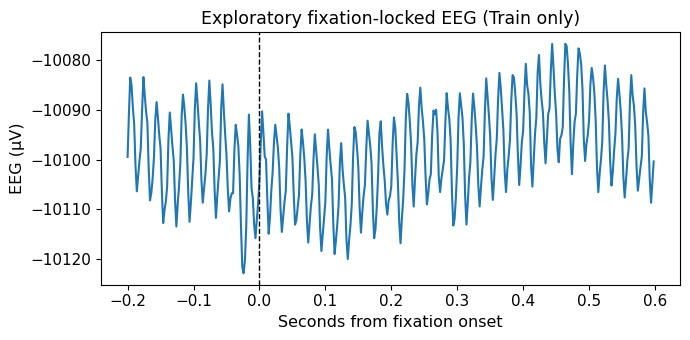

In [6]:
# ======== 05. Fixation-Locked EEG: Descriptive Train-Only Diagnostic =========

training_run = source.loc[source.split.eq('train')].iloc[0]
raw, eye, events, eye_meta, _ = open_run(
    training_run, raw_dir, REQUEST)
try:
    chans = eeg_channels(raw, count=16)
    starts = pd.to_numeric(
        events.loc[events.trial_type.eq('fixation'), 'onset'],
        errors='coerce').dropna().to_numpy()
    starts = starts[(starts > 0.2) &
                    (starts < raw.times[-1] - 0.6)][:80]
    sf = float(raw.info['sfreq'])
    samples = []
    for onset in starts:
        seg = raw.get_data(picks=chans[:1],
                           start=int((onset-0.2)*sf),
                           stop=int((onset+0.6)*sf))[0]
        if len(seg) == int(0.8 * sf) and np.isfinite(seg).all():
            samples.append(seg)
    fig, ax = plt.subplots(figsize=(7, 3.5))
    if samples:
        epochs = np.stack(samples)
        avg = np.mean(epochs, axis=0)
        t = np.arange(len(avg))/sf - 0.2
        ax.plot(t, avg*1e6)
        ax.axvline(0, color='black', ls='--', lw=1)
    ax.set(title='Exploratory fixation-locked EEG (Train only)',
           xlabel='Seconds from fixation onset', ylabel='EEG (µV)')
    fig.tight_layout()
    fig.savefig(output_dir / '03_fixation_locked_diagnostic.png',
                dpi=170)
    plt.show()
finally:
    raw.close()


**06. Save Paired-Window Features and Temporal Evidence**

The executed stage saved **seven named outputs** under `eeg_eye_tracking_fusion/output/`, all now committed with the 18-person run:

| Stage-owned file | Observed content |
| --- | --- |
| `03_features.csv` | **630 source-matched feature rows**, eight numeric window-mean predictors and original participant/task/role/time metadata |
| `03_temporal_sequences.npz` | Separately stored EEG and gaze arrays, each **630 × 6 × 4**, plus Unicode identifiers for safe loading without object deserialisation |
| `03_exclusion_reasons.csv` | Headers only; **zero exclusions** |
| `03_modality_quality.csv` | **36 person/task group counts**, summing to 630 windows |
| `03_feature_quality.csv` | **Eight feature-quality records**: zero non-finite means, Train standard deviations and the constant gaze-availability flag |
| `03_temporal_example.png` | Same-window, six-bin EEG and gaze trends, separately standardised **for display only** |
| `03_fixation_locked_diagnostic.png` | Train-only raw fixation-locked example, **not a verified FRP** |

**Representation and provenance checks:** The saved feature table preserves the **same 630 unique window IDs, roles and timestamps** as the Stage-02 registry. The notebook's execution records two original-unit arrays of shape **(630, 6, 4)**; their compressed NPZ bytes are saved for Notebook 05 and downstream integrity checks. These arrays should not be interpreted as 630 independent participants.

The example temporal plot uses **within-window z-scores solely for visual comparability** between features with different units. The values written to the CSV and NPZ are not standardised by this plotting operation.


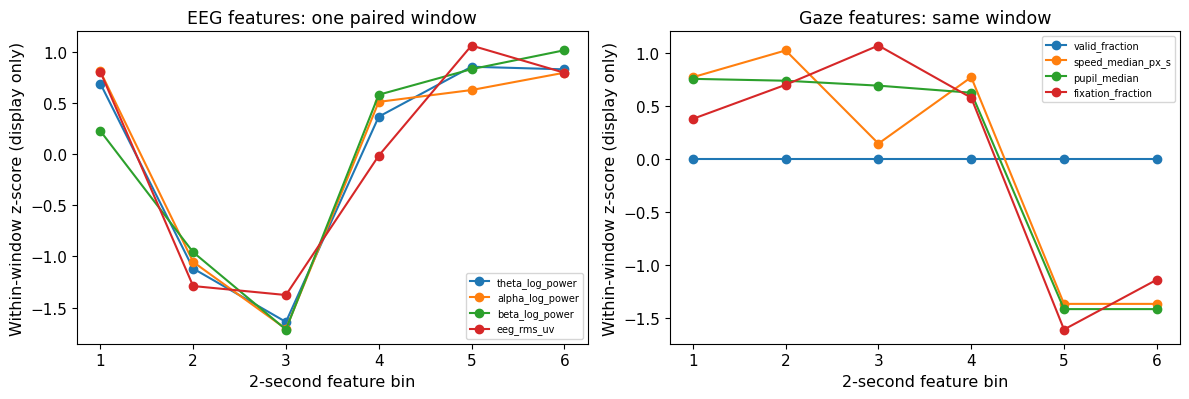

Saved original-unit arrays: (630, 6, 4) (630, 6, 4)


In [7]:
# ====== 06. Save Matched Features and Compact Temporal Representations =======

eeg_seq = np.stack(signal_windows).astype(np.float32)
gaze_seq = np.stack(gaze_windows).astype(np.float32)
if (len(features) != len(accepted) or
        not np.array_equal(features.window_id.astype(str), accepted)):
    raise ValueError('Feature/sequence identity mismatch')
features.to_csv(output_dir / '03_features.csv', index=False)
quality.to_csv(output_dir / '03_exclusion_reasons.csv', index=False)
group_support.to_csv(output_dir / '03_modality_quality.csv',
                     index=False)
feature_quality.to_csv(
    output_dir / '03_feature_quality.csv', index=False)
np.savez_compressed(
    output_dir / '03_temporal_sequences.npz', eeg=eeg_seq,
    gaze=gaze_seq,
    window_id=features.window_id.to_numpy(dtype=str),
    participant_id=features.participant_id.to_numpy(dtype=str),
    task=features.task.to_numpy(dtype=str),
    split=features.split.to_numpy(dtype=str))
# This display standardises each feature within one sample window.
# Saved arrays retain their original, unscaled units for later modelling.
def _display_relative_feature_trends(ax, seq, names, title):
    steps = np.arange(1, seq.shape[0] + 1)
    for col, name in enumerate(names):
        values = np.asarray(seq[:, col], dtype=float)
        available = np.isfinite(values)
        if not available.any():
            continue
        centre = np.mean(values[available])
        spread = np.std(values[available])
        relative = np.full(len(values), np.nan, dtype=float)
        relative[available] = (
            (values[available] - centre) / spread
            if spread > 0 else 0.
        )
        ax.plot(steps, relative, marker="o", label=name)
    ax.set(
        title=title,
        xlabel="2-second feature bin",
        ylabel="Within-window z-score (display only)",
        xticks=steps,
    )
    if ax.lines:
        ax.legend(fontsize=7, loc="best")


fig, axes = plt.subplots(1, 2, figsize=(12, 4.1))
_display_relative_feature_trends(
    axes[0], eeg_seq[0], EEG_FIELDS, "EEG features: one paired window"
)
_display_relative_feature_trends(
    axes[1], gaze_seq[0], GAZE_FIELDS, "Gaze features: same window"
)
fig.tight_layout()
fig.savefig(output_dir / "03_temporal_example.png", dpi=170)
plt.show()
print("Saved original-unit arrays:", eeg_seq.shape, gaze_seq.shape)


**07. Interpretation and Next Dependency**

**Stage-03 conclusion:** Feature extraction completed for **all 630 Stage-02 windows**, with **371 Train, 99 Validation and 160 reserved Test** rows and the original **11/3/4 participant** allocation. All **341 NR** and **289 TSR** windows retain paired EEG and gaze features; there are **no window exclusions, non-finite window-mean values or duplicated source IDs**. Both temporal arrays have the recorded shape **(630, 6, 4)**.

The **Train-only quality report** identifies one non-informative feature, `gaze_valid_fraction`, because its measured value is 1.000 for every window. The other seven window-mean predictors vary across Train examples; this observation says nothing about causal physiology, calibration accuracy, independent EEG–eye drift correction or model performance.

**Next:** [Notebook 04: Unimodal Baselines and Classical EEG–Gaze Fusion](04_unimodal_baselines_and_classical_fusion.ipynb) will fit the predefined seven classical/simple-fusion candidates using **371 Train windows from 11 people**, compare them on **99 Validation windows from three people**, and produce descriptive per-person Validation summaries. The **160 Test windows from four people** remain reserved and must not influence training or model selection.

The result of this stage is **a verified feature representation**, not a classification result. Validation scores, rankings and model interpretations can only be reported after Notebook 04 executes on the expanded cohort.


In [8]:
# ================== 07. Interpretation and Next Dependency ===================

print("Next: 04_unimodal_baselines_and_classical_fusion.ipynb")
download_outputs_from_colab("eeg_eye_tracking_fusion/output", "03")


Next: 04_unimodal_baselines_and_classical_fusion.ipynb
------------------------------------------------------------------------
Notebook 03
Files packaged: 7
  + 03_exclusion_reasons.csv
  + 03_feature_quality.csv
  + 03_features.csv
  + 03_fixation_locked_diagnostic.png
  + 03_modality_quality.csv
  + 03_temporal_example.png
  + 03_temporal_sequences.npz
Download ZIP from Colab Contents: /content/eeg_eye_tracking_fusion_Notebook_03_Outputs.zip
